<a href="https://colab.research.google.com/github/aziz-belloumi/AI_testing/blob/main/perceptron.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
import torch
from torchvision import datasets
from torchvision.transforms import ToTensor
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt
from torch import optim
from torch import nn


trainData = datasets.FashionMNIST(
    root = 'FashionMNIST' ,
    train = True ,
    download = True ,
    transform = ToTensor()
)
testData = datasets.FashionMNIST(
    root = 'FashionMNIST' ,
    train = False ,
    download = True ,
    transform = ToTensor()
)


100%|██████████| 26.4M/26.4M [00:02<00:00, 12.9MB/s]


Extracting FashionMNIST/FashionMNIST/raw/train-images-idx3-ubyte.gz to FashionMNIST/FashionMNIST/raw



100%|██████████| 29.5k/29.5k [00:00<00:00, 209kB/s]


Extracting FashionMNIST/FashionMNIST/raw/train-labels-idx1-ubyte.gz to FashionMNIST/FashionMNIST/raw



100%|██████████| 4.42M/4.42M [00:01<00:00, 3.82MB/s]


Extracting FashionMNIST/FashionMNIST/raw/t10k-images-idx3-ubyte.gz to FashionMNIST/FashionMNIST/raw



100%|██████████| 5.15k/5.15k [00:00<00:00, 5.10MB/s]

Extracting FashionMNIST/FashionMNIST/raw/t10k-labels-idx1-ubyte.gz to FashionMNIST/FashionMNIST/raw



Feature batch shape : torch.Size([64, 1, 28, 28])
labels batch shape : torch.Size([64])


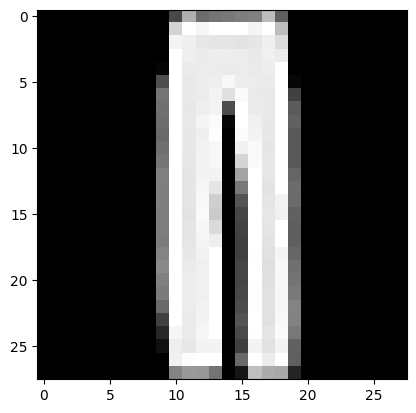

Label : tensor(1)


In [4]:
trainDataLoader = DataLoader(trainData , batch_size = 64 , shuffle = True )
testDataLoader = DataLoader(testData , batch_size = 64 , shuffle = True )
trainFeatures , trainLabels = next(iter(trainDataLoader))
print(f"Feature batch shape : {trainFeatures.size()}")
print(f"labels batch shape : {trainLabels.size()}")
img = trainFeatures[0].squeeze()
label = trainLabels[0]
plt.imshow(img , cmap = "gray")
plt.show()
print("Label :" , label)

In [5]:
device = (
    "cuda"
    if torch.cuda.is_available()
    else "mps"
    if torch.backends.mps.is_available()
    else "cpu"
)
print(f"Using {device} device")

Using cpu device


In [6]:
class NeuralNetwork(nn.Module) :
  def __init__(self) :
    super().__init__()
    self.flatten = nn.Flatten()
    self.Linear_relu_stack = nn.Sequential(
        nn.Linear(28*28,512) ,
        nn.ReLU() ,
        nn.Linear(512,512) ,
        nn.ReLU() ,
        nn.Linear(512,10),
    )
  def forward(self,x) :
      x = self.flatten(x)
      logits = self.Linear_relu_stack(x)
      return logits

In [7]:
model = NeuralNetwork().to(device)
print(model)

NeuralNetwork(
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (Linear_relu_stack): Sequential(
    (0): Linear(in_features=784, out_features=512, bias=True)
    (1): ReLU()
    (2): Linear(in_features=512, out_features=512, bias=True)
    (3): ReLU()
    (4): Linear(in_features=512, out_features=10, bias=True)
  )
)


In [8]:
lossFunction = nn.CrossEntropyLoss()
optimizer = optim.SGD(model.parameters() , lr = 0.001 , momentum = 0.9)

In [11]:
# Training loop
epochs = 5
for epoch in range(epochs):
    print(f"Epoch {epoch + 1}\n-------------------------------")
    total_loss = 0

    for batch in trainDataLoader:
        images, labels = batch
        images, labels = images.to(device), labels.to(device)

        # forward + backward + optimize
        predictions = model.forward(images)
        loss = lossFunction(predictions, labels)

        # Backward pass
        optimizer.zero_grad()  # Clear previous gradients
        loss.backward()        # Compute gradients
        optimizer.step()       # Update parameters

        total_loss += loss.item()

    # Average loss for the epoch
    print(f"Loss: {total_loss / len(trainDataLoader):.4f}")

print("Training Complete!")

Epoch 1
-------------------------------
Loss: 0.4652
Epoch 2
-------------------------------
Loss: 0.4483
Epoch 3
-------------------------------
Loss: 0.4361
Epoch 4
-------------------------------
Loss: 0.4250
Epoch 5
-------------------------------
Loss: 0.4149
Training Complete!


In [12]:
# Initialize variables to track the number of correct predictions and total samples
correct = 0

for testFeatures, testLabels in testDataLoader:
    # Forward pass: Get model predictions
    predictions = model(testFeatures)

    # Get the predicted class (the class with the highest probability)
    _, predicted = torch.max(predictions, 1)

    # Count the correct predictions
    correct += (predicted == testLabels).sum().item()

accuracy = correct / 10000 * 100
print(f"Test Accuracy: {accuracy}%")

Test Accuracy: 84.23%
